# Практическая работа 5
Машинное обучение в анализе данных с использованием Spark MLlib

Албахтин И.В., ИНБО-12-23. Учебная часть: Online Shoppers и Seoul Bike. Самостоятельная часть: Calories. Все обучаемые преобразования подбираются на train; valid служит выбору, test — итоговой проверке.

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession
import os,platform,subprocess,hashlib
os.environ['MPLBACKEND']='Agg'
spark=(SparkSession.builder.master('local[*]').appName('TIABD_Practice_5_Albakhtin_IV')
    .config('spark.driver.memory','1536m').config('spark.sql.shuffle.partitions','4')
    .config('spark.sql.session.timeZone','UTC').config('spark.ui.bindAddress','0.0.0.0').getOrCreate())


26/10/26 00:41:51 WARN Utils: Your hostname, tiabd-albakhtin-iv resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/26 00:41:51 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 00:41:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Практический блок 3.1. Импорты и рабочие каталоги

In [2]:
from pathlib import Path
from time import perf_counter
import csv
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F, Window
from pyspark.sql.types import (
    StructType, StructField, LongType, IntegerType,
    DoubleType, StringType, BooleanType
)
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import (
    SQLTransformer, StringIndexer, OneHotEncoder,
    VectorAssembler, StandardScaler, PolynomialExpansion, PCA
)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import BinaryClassificationEvaluator, RegressionEvaluator

from sklearn.metrics import (
    precision_recall_curve, roc_curve, confusion_matrix,
    silhouette_score
)

SEED = 42
ROOT = Path.cwd()
WORK = ROOT / "work/pr5"
OUT = ROOT / "results/pr5"
WORK.mkdir(parents=True,exist_ok=True)
OUT.mkdir(parents=True,exist_ok=True)

SHOP_SOURCE = ROOT / "data/online_shoppers_intention.csv"
BIKE_SOURCE = ROOT / "data/SeoulBikeData.csv"

for path in [SHOP_SOURCE, BIKE_SOURCE]:
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

sc = spark.sparkContext
sc.setLogLevel("WARN")
print("Spark:", spark.version)
print("Master:", sc.master)
print("Spark UI:", sc.uiWebUrl)
MODELS=ROOT/"models/pr5"
MODELS.mkdir(parents=True,exist_ok=True)


Spark: 3.5.7
Master: local[*]
Spark UI: http://10.0.2.15:4040


## Практический блок 3.2. Устойчивый row_id для интернет-сессий

In [3]:
SHOP_WORK = WORK / "online_shoppers_with_id.csv"

with SHOP_SOURCE.open("r", encoding="utf-8-sig", newline="") as src, \
     SHOP_WORK.open("w", encoding="utf-8", newline="") as dst:
    reader = csv.reader(src)
    writer = csv.writer(dst)
    header = next(reader)
    writer.writerow(["row_id"] + header)
    for row_id, row in enumerate(reader, start=1):
        writer.writerow([row_id] + row)

## Практический блок 3.3. Явные схемы и чтение CSV

In [4]:
shop_schema = StructType([
    StructField("row_id", LongType(), False),
    StructField("Administrative", DoubleType(), False),
    StructField("Administrative_Duration", DoubleType(), False),
    StructField("Informational", DoubleType(), False),
    StructField("Informational_Duration", DoubleType(), False),
    StructField("ProductRelated", DoubleType(), False),
    StructField("ProductRelated_Duration", DoubleType(), False),
    StructField("BounceRates", DoubleType(), False),
    StructField("ExitRates", DoubleType(), False),
    StructField("PageValues", DoubleType(), False),
    StructField("SpecialDay", DoubleType(), False),
    StructField("Month", StringType(), False),
    StructField("OperatingSystems", IntegerType(), False),
    StructField("Browser", IntegerType(), False),
    StructField("Region", IntegerType(), False),
    StructField("TrafficType", IntegerType(), False),
    StructField("VisitorType", StringType(), False),
    StructField("Weekend", BooleanType(), False),
    StructField("Revenue", BooleanType(), False),
])

bike_schema = StructType([
    StructField("date_text", StringType(), False),
    StructField("label", DoubleType(), False),
    StructField("hour", IntegerType(), False),
    StructField("temperature", DoubleType(), False),
    StructField("humidity", DoubleType(), False),
    StructField("wind_speed", DoubleType(), False),
    StructField("visibility", DoubleType(), False),
    StructField("dew_point", DoubleType(), False),
    StructField("solar_radiation", DoubleType(), False),
    StructField("rainfall", DoubleType(), False),
    StructField("snowfall", DoubleType(), False),
    StructField("season", StringType(), False),
    StructField("holiday", StringType(), False),
    StructField("functioning_day", StringType(), False),
])

shop_raw = (spark.read
    .option("header", True)
    .option("mode", "FAILFAST")
    .schema(shop_schema)
    .csv(SHOP_WORK.resolve().as_posix()))

bike_raw = (spark.read
    .option("header", True)
    .option("encoding", "ISO-8859-1")
    .option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .schema(bike_schema)
    .csv(BIKE_SOURCE.resolve().as_posix()))

print("Online Shoppers:", shop_raw.count(), "строк")
print("Seoul Bike:", bike_raw.count(), "строк")
shop_raw.printSchema()
bike_raw.printSchema()

Online Shoppers: 12330 строк
Seoul Bike: 8760 строк
root
 |-- row_id: long (nullable = true)
 |-- Administrative: double (nullable = true)
 |-- Administrative_Duration: double (nullable = true)
 |-- Informational: double (nullable = true)
 |-- Informational_Duration: double (nullable = true)
 |-- ProductRelated: double (nullable = true)
 |-- ProductRelated_Duration: double (nullable = true)
 |-- BounceRates: double (nullable = true)
 |-- ExitRates: double (nullable = true)
 |-- PageValues: double (nullable = true)
 |-- SpecialDay: double (nullable = true)
 |-- Month: string (nullable = true)
 |-- OperatingSystems: integer (nullable = true)
 |-- Browser: integer (nullable = true)
 |-- Region: integer (nullable = true)
 |-- TrafficType: integer (nullable = true)
 |-- VisitorType: string (nullable = true)
 |-- Weekend: boolean (nullable = true)
 |-- Revenue: boolean (nullable = true)

root
 |-- date_text: string (nullable = true)
 |-- label: double (nullable = true)
 |-- hour: integer (nu

## Практический блок 3.4. Контроль строк, ключей и пропусков

In [5]:
def null_counts(df):
    return df.select(*[
        F.sum(F.col(c).isNull().cast("int")).alias(c)
        for c in df.columns
    ]).first().asDict()


shop_raw.groupBy("Revenue").count().orderBy("Revenue").show()
bike_raw.groupBy("functioning_day").agg(
    F.count("*").alias("n"),
    F.min("label").alias("min_target"),
    F.max("label").alias("max_target")
).show()
assert shop_raw.count()==12330 and bike_raw.count()==8760
assert not any(null_counts(shop_raw).values()) and not any(null_counts(bike_raw).values())


+-------+-----+
|Revenue|count|
+-------+-----+
|  false|10422|
|   true| 1908|
+-------+-----+



26/10/26 00:41:56 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Rented Bike Count, Functioning Day
 Schema: label, functioning_day
Expected: label but found: Rented Bike Count
CSV file: file:///home/albakhtin/tiabd/АлбахтинИВ/ML/data/SeoulBikeData.csv


+---------------+----+----------+----------+
|functioning_day|   n|min_target|max_target|
+---------------+----+----------+----------+
|             No| 295|       0.0|       0.0|
|            Yes|8465|       2.0|    3556.0|
+---------------+----+----------+----------+



26/10/26 00:41:56 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Date, Rented Bike Count, Hour, Temperature(°C), Humidity(%), Wind speed (m/s), Visibility (10m), Dew point temperature(°C), Solar Radiation (MJ/m2), Rainfall(mm), Snowfall (cm), Seasons, Holiday, Functioning Day
 Schema: date_text, label, hour, temperature, humidity, wind_speed, visibility, dew_point, solar_radiation, rainfall, snowfall, season, holiday, functioning_day
Expected: date_text but found: Date
CSV file: file:///home/albakhtin/tiabd/АлбахтинИВ/ML/data/SeoulBikeData.csv


## 4.3. Преобразование, разбиение и веса классов

In [6]:
SHOP_LOG_SOURCE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration"
]
SHOP_LOG = ["log_" + c for c in SHOP_LOG_SOURCE]
SHOP_NUM_BASE = SHOP_LOG + ["BounceRates", "ExitRates", "SpecialDay"]
SHOP_CAT = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

shop = shop_raw.withColumn("label", F.col("Revenue").cast("double"))
for c in ["OperatingSystems", "Browser", "Region", "TrafficType", "Weekend"]:
    shop = shop.withColumn(c, F.col(c).cast("string"))

order_key = F.sha2(F.concat_ws(
    ":", F.col("row_id").cast("string"), F.lit(str(SEED))
), 256)
rank_window = Window.partitionBy("label").orderBy(order_key, "row_id")
class_window = Window.partitionBy("label")

shop_split = (shop
    .withColumn("_rank", F.row_number().over(rank_window))
    .withColumn("_size", F.count("*").over(class_window))
    .withColumn(
        "split",
        F.when(F.col("_rank") <= F.floor(F.col("_size") * 0.60), "train")
         .when(F.col("_rank") <= F.floor(F.col("_size") * 0.80), "valid")
         .otherwise("test")
    )
    .drop("_rank", "_size")
    .cache())

shop_split.groupBy("split", "label").count().orderBy("split", "label").show()

shop_train = shop_split.filter("split = 'train'").drop("split")
shop_valid = shop_split.filter("split = 'valid'").drop("split")
shop_test = shop_split.filter("split = 'test'").drop("split")

counts = {int(r["label"]): r["count"]
          for r in shop_train.groupBy("label").count().collect()}
train_n = sum(counts.values())
weight_0 = train_n / (2.0 * counts[0])
weight_1 = train_n / (2.0 * counts[1])
shop_train = shop_train.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(weight_1)).otherwise(F.lit(weight_0))
)
print("Веса классов:", weight_0, weight_1)

+-----+-----+-----+
|split|label|count|
+-----+-----+-----+
| test|  0.0| 2085|
| test|  1.0|  382|
|train|  0.0| 6253|
|train|  1.0| 1144|
|valid|  0.0| 2084|
|valid|  1.0|  382|
+-----+-----+-----+

Веса классов: 0.5914760914760915 3.2329545454545454


## Практический блок 4.5. Pipeline двух классификаторов

In [7]:
def shop_pipeline(kind, include_page_values=True):
    expressions = [
        f"log1p(`{source}`) AS `{target}`"
        for source, target in zip(SHOP_LOG_SOURCE, SHOP_LOG)
    ]
    log_stage = SQLTransformer(
        statement="SELECT *, " + ", ".join(expressions) + " FROM __THIS__"
    )

    index_cols = [c + "_idx" for c in SHOP_CAT]
    encoded_cols = [c + "_ohe" for c in SHOP_CAT]
    indexer = StringIndexer(
        inputCols=SHOP_CAT,
        outputCols=index_cols,
        handleInvalid="keep",
        stringOrderType="alphabetAsc"
    )
    encoder = OneHotEncoder(
        inputCols=index_cols,
        outputCols=encoded_cols,
        handleInvalid="keep",
        dropLast=False
    )

    numeric = SHOP_NUM_BASE + (["PageValues"] if include_page_values else [])
    if kind == "LR":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features_raw"
        )
        scaler = StandardScaler(
            inputCol="features_raw", outputCol="features",
            withMean=False, withStd=True
        )
        estimator = LogisticRegression(
            maxIter=100, regParam=0.05, elasticNetParam=0.0,
            standardization=False, weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, scaler, estimator]
    elif kind == "RF":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features"
        )
        estimator = RandomForestClassifier(
            numTrees=80, maxDepth=8, maxBins=64,
            featureSubsetStrategy="sqrt", seed=SEED,
            weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, estimator]
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages)


def binary_scores(model, df):
    return (model.transform(df)
        .withColumn("score", vector_to_array("probability")[1])
        .select("row_id", "label", "score"))


def binary_metrics(pred, threshold=0.5, ranking=True):
    decision = F.col("score") >= F.lit(float(threshold))
    y = F.col("label") == 1.0
    values = pred.agg(
        F.sum((decision & y).cast("long")).alias("tp"),
        F.sum((decision & ~y).cast("long")).alias("fp"),
        F.sum((~decision & y).cast("long")).alias("fn"),
        F.sum((~decision & ~y).cast("long")).alias("tn")
    ).first().asDict()

    tp, fp, fn, tn = (values[k] for k in ["tp", "fp", "fn", "tn"])
    n = tp + fp + fn + tn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    result = {
        "accuracy": (tp + tn) / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn
    }
    if ranking:
        for metric in ["areaUnderROC", "areaUnderPR"]:
            result[metric] = BinaryClassificationEvaluator(
                labelCol="label", rawPredictionCol="score", metricName=metric
            ).evaluate(pred)
    return result

## 4.6. Метрики и обучение

In [8]:
shop_models = {}
shop_valid_predictions = {}
shop_rows = []

for name, kind in [("Логистическая регрессия", "LR"),
                   ("Случайный лес", "RF")]:
    sc.setJobGroup("P5_CLASS_" + kind, "Классификация: " + name)
    t0 = perf_counter()
    model = shop_pipeline(kind, include_page_values=True).fit(shop_train)
    fit_s = perf_counter() - t0
    pred = binary_scores(model, shop_valid).cache()
    pred.count()
    row = {"model": name, "fit_s": fit_s, **binary_metrics(pred)}
    shop_models[name] = model
    shop_valid_predictions[name] = pred
    shop_rows.append(row)

shop_validation = pd.DataFrame(shop_rows).sort_values("areaUnderPR", ascending=False)
print(shop_validation.round(4).to_string(index=False))
BEST_SHOP_NAME = str(shop_validation.iloc[0]["model"])
BEST_SHOP = shop_models[BEST_SHOP_NAME]

26/10/26 00:41:58 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


26/10/26 00:41:59 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


26/10/26 00:42:04 WARN DAGScheduler: Broadcasting large task binary with size 1269.9 KiB


26/10/26 00:42:05 WARN DAGScheduler: Broadcasting large task binary with size 1869.2 KiB


26/10/26 00:42:05 WARN DAGScheduler: Broadcasting large task binary with size 1434.2 KiB


26/10/26 00:42:05 WARN DAGScheduler: Broadcasting large task binary with size 1438.3 KiB
26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1448.4 KiB


26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB
26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB


                  model  fit_s  accuracy  precision  recall     f1  tp  fp  fn   tn  areaUnderROC  areaUnderPR
          Случайный лес 2.8983    0.8698     0.5509  0.8639 0.6728 330 269  52 1815        0.9284       0.7212
Логистическая регрессия 2.9206    0.8204     0.4529  0.7670 0.5695 293 354  89 1730        0.8950       0.6102


## 4.7. Выбор порога и однократный test

In [9]:
valid_pd = shop_valid_predictions[BEST_SHOP_NAME].toPandas()
precision, recall, thresholds = precision_recall_curve(
    valid_pd["label"], valid_pd["score"]
)
f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_index = int(np.nanargmax(f1_values[:-1]))
SHOP_THRESHOLD = float(thresholds[best_index])
print("Выбранная модель:", BEST_SHOP_NAME)
print("Порог по максимуму F1 на valid:", round(SHOP_THRESHOLD, 4))
print(binary_metrics(
    shop_valid_predictions[BEST_SHOP_NAME], SHOP_THRESHOLD, ranking=True
))

shop_test_scores = binary_scores(BEST_SHOP, shop_test).cache()
shop_test_scores.count()
print("TEST:", binary_metrics(shop_test_scores, SHOP_THRESHOLD, ranking=True))

Выбранная модель: Случайный лес
Порог по максимуму F1 на valid: 0.5516


26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1435.3 KiB
26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1448.4 KiB


26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB
26/10/26 00:42:06 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB


{'accuracy': 0.8832116788321168, 'precision': 0.587037037037037, 'recall': 0.8298429319371727, 'f1': 0.6876355748373102, 'tp': 317, 'fp': 223, 'fn': 65, 'tn': 1861, 'areaUnderROC': 0.9283647033996241, 'areaUnderPR': 0.7211833942294339}


26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1434.2 KiB
26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1438.3 KiB


26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1448.4 KiB
26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB


TEST: {'accuracy': 0.8771787596270775, 'precision': 0.5758157389635317, 'recall': 0.7853403141361257, 'f1': 0.6644518272425249, 'tp': 300, 'fp': 221, 'fn': 82, 'tn': 1864, 'areaUnderROC': 0.9050045827212577, 'areaUnderPR': 0.6864525218870905}


26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB


## 4.8. Кривые качества

In [10]:
# Графики классификации строятся по небольшой таблице valid/test.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name, color in [("Логистическая регрессия", "tab:blue"),
                    ("Случайный лес", "tab:red")]:
    local = shop_valid_predictions[name].toPandas()
    p, r, _ = precision_recall_curve(local["label"], local["score"])
    ax.plot(r, p, label=name, color=color, linewidth=2)
ax.axhline(valid_pd["label"].mean(), linestyle="--", color="gray",
           label="Доля положительного класса")
ax.set(xlabel="Recall", ylabel="Precision",
       title="Precision–Recall-кривые на valid")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "classification_pr.png", dpi=160)
plt.show()

final_pd = shop_test_scores.toPandas()
final_pred = (final_pd["score"] >= SHOP_THRESHOLD).astype(int)
cm = confusion_matrix(final_pd["label"].astype(int), final_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
ax.set_xticks([0, 1], ["Нет покупки", "Покупка"])
ax.set_yticks([0, 1], ["Нет покупки", "Покупка"])
ax.set(xlabel="Решение модели", ylabel="Факт", title="Матрица ошибок на test")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "classification_confusion.png", dpi=160)
plt.show()

26/10/26 00:42:07 WARN DAGScheduler: Broadcasting large task binary with size 1435.3 KiB
26/10/26 00:42:08 WARN DAGScheduler: Broadcasting large task binary with size 1435.3 KiB


## 4.9. Важность признаков и абляция PageValues

In [11]:
# Проверка чувствительности к PageValues на той же valid.
rf_without_page_values = shop_pipeline("RF", include_page_values=False).fit(shop_train)
without_scores = binary_scores(rf_without_page_values, shop_valid)
print("RF с PageValues:",
      binary_metrics(shop_valid_predictions["Случайный лес"], ranking=True)["areaUnderPR"])
print("RF без PageValues:",
      binary_metrics(without_scores, ranking=True)["areaUnderPR"])

26/10/26 00:42:09 WARN DAGScheduler: Broadcasting large task binary with size 1282.2 KiB


26/10/26 00:42:09 WARN DAGScheduler: Broadcasting large task binary with size 1912.2 KiB


26/10/26 00:42:10 WARN DAGScheduler: Broadcasting large task binary with size 1448.4 KiB
26/10/26 00:42:10 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB


26/10/26 00:42:10 WARN DAGScheduler: Broadcasting large task binary with size 1443.5 KiB
26/10/26 00:42:10 WARN DAGScheduler: Broadcasting large task binary with size 1501.5 KiB


RF с PageValues: 0.7211880397894632


26/10/26 00:42:11 WARN DAGScheduler: Broadcasting large task binary with size 1515.7 KiB


RF без PageValues: 0.3898252934850925


26/10/26 00:42:11 WARN DAGScheduler: Broadcasting large task binary with size 1515.7 KiB


## 5.2. Временные признаки и части выборки

In [12]:
bike = (bike_raw
    .withColumn("date", F.to_date("date_text", "dd/MM/yyyy"))
    .drop("date_text")
    .filter(F.col("functioning_day") == "Yes")
    .withColumn("weekday", F.dayofweek("date").cast("string"))
    .withColumn("hour_sin",
                F.sin(F.lit(2.0 * math.pi) * F.col("hour") / F.lit(24.0)))
    .withColumn("hour_cos",
                F.cos(F.lit(2.0 * math.pi) * F.col("hour") / F.lit(24.0)))
    .withColumn("month_sin",
                F.sin(F.lit(2.0 * math.pi) * F.month("date") / F.lit(12.0)))
    .withColumn("month_cos",
                F.cos(F.lit(2.0 * math.pi) * F.month("date") / F.lit(12.0)))
    .withColumn("day_index",
                F.datediff("date", F.lit("2017-12-01").cast("date")).cast("double")))

bike_train = bike.filter("date < DATE '2018-08-01'").cache()
bike_valid = bike.filter(
    "date >= DATE '2018-08-01' AND date < DATE '2018-10-01'"
).cache()
bike_test = bike.filter("date >= DATE '2018-10-01'").cache()

for name, df in [("train", bike_train), ("valid", bike_valid), ("test", bike_test)]:
    print(name, df.count())
    df.agg(F.min("date"), F.max("date")).show()

26/10/26 00:42:11 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Date, Rented Bike Count, Hour, Temperature(°C), Humidity(%), Wind speed (m/s), Visibility (10m), Dew point temperature(°C), Solar Radiation (MJ/m2), Rainfall(mm), Snowfall (cm), Seasons, Holiday, Functioning Day
 Schema: date_text, label, hour, temperature, humidity, wind_speed, visibility, dew_point, solar_radiation, rainfall, snowfall, season, holiday, functioning_day
Expected: date_text but found: Date
CSV file: file:///home/albakhtin/tiabd/АлбахтинИВ/ML/data/SeoulBikeData.csv


train 5784
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2017-12-01|2018-07-31|
+----------+----------+

valid 1368
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2018-08-01|2018-09-29|
+----------+----------+



test 1313
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2018-10-01|2018-11-30|
+----------+----------+



26/10/26 00:42:11 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Date, Rented Bike Count, Hour, Temperature(°C), Humidity(%), Wind speed (m/s), Visibility (10m), Dew point temperature(°C), Solar Radiation (MJ/m2), Rainfall(mm), Snowfall (cm), Seasons, Holiday, Functioning Day
 Schema: date_text, label, hour, temperature, humidity, wind_speed, visibility, dew_point, solar_radiation, rainfall, snowfall, season, holiday, functioning_day
Expected: date_text but found: Date
CSV file: file:///home/albakhtin/tiabd/АлбахтинИВ/ML/data/SeoulBikeData.csv
26/10/26 00:42:11 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Date, Rented Bike Count, Hour, Temperature(°C), Humidity(%), Wind speed (m/s), Visibility (10m), Dew point temperature(°C), Solar Radiation (MJ/m2), Rainfall(mm), Snowfall (cm), Seasons, Holiday, Functioning Day
 Schema: date_text, label, hour, temperature, humidity, wind_speed, visibility, dew_point, solar_radiation, rainfall,

## Практический блок 5.4. Pipeline регрессоров

In [13]:
BIKE_CAT = ["season", "holiday", "weekday"]
BIKE_NUM = [
    "temperature", "humidity", "wind_speed", "visibility",
    "dew_point", "solar_radiation", "rainfall", "snowfall",
    "hour_sin", "hour_cos", "month_sin", "month_cos"
]
BIKE_RF_NUM = BIKE_NUM + ["day_index"]
POLY_SOURCE = ["temperature", "humidity", "solar_radiation", "hour_sin", "hour_cos"]
POLY_REST = [c for c in BIKE_NUM if c not in POLY_SOURCE]


def bike_pipeline(kind):
    index_cols = [c + "_idx" for c in BIKE_CAT]
    encoded_cols = [c + "_ohe" for c in BIKE_CAT]
    indexer = StringIndexer(
        inputCols=BIKE_CAT, outputCols=index_cols,
        handleInvalid="keep", stringOrderType="alphabetAsc"
    )
    encoder = OneHotEncoder(
        inputCols=index_cols, outputCols=encoded_cols,
        handleInvalid="keep", dropLast=False
    )
    stages = [indexer, encoder]

    if kind == "LINEAR":
        stages += [
            VectorAssembler(
                inputCols=BIKE_NUM + encoded_cols, outputCol="features_raw"
            ),
            StandardScaler(
                inputCol="features_raw", outputCol="features",
                withMean=False, withStd=True
            ),
            LinearRegression(
                maxIter=150, regParam=0.1, elasticNetParam=0.0,
                standardization=False
            )
        ]
    elif kind == "POLY":
        stages += [
            VectorAssembler(inputCols=POLY_SOURCE, outputCol="poly_input"),
            PolynomialExpansion(
                degree=2, inputCol="poly_input", outputCol="poly_features"
            ),
            VectorAssembler(
                inputCols=["poly_features"] + POLY_REST + encoded_cols,
                outputCol="features_raw"
            ),
            StandardScaler(
                inputCol="features_raw", outputCol="features",
                withMean=False, withStd=True
            ),
            LinearRegression(
                maxIter=200, regParam=1.0, elasticNetParam=0.0,
                standardization=False
            )
        ]
    elif kind == "RF":
        stages += [
            VectorAssembler(
                inputCols=BIKE_RF_NUM + encoded_cols, outputCol="features"
            ),
            RandomForestRegressor(
                numTrees=120, maxDepth=12, maxBins=64,
                minInstancesPerNode=5, featureSubsetStrategy="0.7",
                seed=SEED
            )
        ]
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages)

## 5.5. Метрики и базовые правила

In [14]:
def regression_metrics(pred):
    result = {}
    for metric in ["rmse", "mae", "r2"]:
        result[metric] = RegressionEvaluator(
            labelCol="label", predictionCol="prediction", metricName=metric
        ).evaluate(pred)
    result["negative_share"] = pred.agg(
        F.avg((F.col("prediction") < 0).cast("double"))
    ).first()[0]
    return result

train_mean = bike_train.agg(F.avg("label")).first()[0]
hour_means = bike_train.groupBy("hour").agg(
    F.avg("label").alias("hour_mean")
)

def bike_baseline(df, by_hour=False):
    if not by_hour:
        return df.withColumn("prediction", F.lit(train_mean))
    return (df.join(hour_means, "hour", "left")
        .withColumn("prediction", F.coalesce("hour_mean", F.lit(train_mean))))

## 5.6. Обучение и сравнение

In [15]:
bike_models = {}
bike_rows = []
bike_valid_predictions = {}

for name, kind in [("Линейная регрессия", "LINEAR"),
                   ("Полиномиальная регрессия", "POLY"),
                   ("Случайный лес", "RF")]:
    sc.setJobGroup("P5_REG_" + kind, "Регрессия: " + name)
    t0 = perf_counter()
    model = bike_pipeline(kind).fit(bike_train)
    fit_s = perf_counter() - t0
    pred = model.transform(bike_valid).cache()
    pred.select(F.avg("prediction")).first()
    bike_models[name] = model
    bike_valid_predictions[name] = pred
    bike_rows.append({"model": name, "fit_s": fit_s, **regression_metrics(pred)})

for name, by_hour in [("Среднее train", False), ("Среднее по часу", True)]:
    bike_rows.append({"model": name, **regression_metrics(bike_baseline(bike_valid, by_hour))})

bike_validation = pd.DataFrame(bike_rows).sort_values("rmse")
print(bike_validation.round(3).to_string(index=False))

learned = bike_validation[bike_validation["model"].isin(bike_models)]
BEST_BIKE_NAME = str(learned.iloc[0]["model"])
BEST_BIKE = bike_models[BEST_BIKE_NAME]
print("Выбрана модель:", BEST_BIKE_NAME)

bike_test_prediction = (BEST_BIKE.transform(bike_test)
    .select("date", "hour", "label", "prediction")
    .withColumn("residual", F.col("label") - F.col("prediction"))
    .cache())
print("TEST:", regression_metrics(bike_test_prediction))

26/10/26 00:42:12 WARN Instrumentation: [d2fcd534] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/26 00:42:13 WARN Instrumentation: [8cf61851] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/26 00:42:14 WARN DAGScheduler: Broadcasting large task binary with size 1512.0 KiB


26/10/26 00:42:15 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB


26/10/26 00:42:16 WARN DAGScheduler: Broadcasting large task binary with size 4.9 MiB


...

26/10/26 00:42:25 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB


26/10/26 00:42:27 WARN DAGScheduler: Broadcasting large task binary with size 1718.7 KiB


26/10/26 00:42:27 WARN DAGScheduler: Broadcasting large task binary with size 1870.8 KiB


                   model  fit_s    rmse     mae     r2  negative_share
           Случайный лес 14.272 285.735 196.853  0.801           0.000
Полиномиальная регрессия  0.453 401.083 296.099  0.607           0.002
      Линейная регрессия  0.451 525.596 421.225  0.326           0.004
         Среднее по часу    NaN 559.135 429.727  0.237           0.000
           Среднее train    NaN 717.361 539.660 -0.256           0.000
Выбрана модель: Случайный лес


TEST: {'rmse': 299.6597639857966, 'mae': 196.98995326070087, 'r2': 0.7149742070696499, 'negative_share': 0.0}


## 5.7. Проверка итоговой модели

In [16]:
# Графики регрессии строятся по тестовой таблице
reg_local = bike_test_prediction.orderBy("date", "hour").toPandas()
reg_local["timestamp"] = (
    pd.to_datetime(reg_local["date"]) +
    pd.to_timedelta(reg_local["hour"], unit="h")
)

fig, ax = plt.subplots(figsize=(6.4, 5.0))
ax.scatter(reg_local["label"], reg_local["prediction"], s=12, alpha=0.35)
limit = max(reg_local["label"].max(), reg_local["prediction"].max())
ax.plot([0, limit], [0, limit], "-", color="tab:red")
ax.set(xlabel="Фактическое число аренд", ylabel="Прогноз",
       title="Факт и прогноз на test")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "regression_scatter.png", dpi=160)
plt.show()

week = reg_local[reg_local["timestamp"] < reg_local["timestamp"].min() + pd.Timedelta(days=7)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(week["timestamp"], week["label"], label="Факт")
ax.plot(week["timestamp"], week["prediction"], label="Прогноз")
ax.set(xlabel="Дата и час", ylabel="Число аренд",
       title="Первая неделя тестового периода")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "regression_week.png", dpi=160)
plt.show()

## Практический блок 6.2. Подготовка вектора

In [17]:
CLUSTER_LOG_SOURCE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration"
]
CLUSTER_LOG = ["cluster_log_" + c for c in CLUSTER_LOG_SOURCE]
CLUSTER_RATE = ["BounceRates", "ExitRates"]

cluster_expressions = [
    f"log1p(`{source}`) AS `{target}`"
    for source, target in zip(CLUSTER_LOG_SOURCE, CLUSTER_LOG)
]
cluster_prep = Pipeline(stages=[
    SQLTransformer(
        statement="SELECT *, " + ", ".join(cluster_expressions) + " FROM __THIS__"
    ),
    VectorAssembler(
        inputCols=CLUSTER_LOG + CLUSTER_RATE,
        outputCol="cluster_raw"
    ),
    StandardScaler(
        inputCol="cluster_raw", outputCol="features",
        withMean=True, withStd=True
    )
])

cluster_prep_model = cluster_prep.fit(shop_raw)
shop_vectors = cluster_prep_model.transform(shop_raw).select("row_id", "features").cache()

sample_order = F.sha2(F.concat_ws(
    ":", F.col("row_id").cast("string"), F.lit(str(SEED))
), 256)
cluster_sample = shop_vectors.orderBy(sample_order, "row_id").limit(4000).cache()
cluster_sample.count()

4000

## 6.3. KMeans и выбор k

In [18]:
k_models = {}
k_rows = []

for k in range(2, 9):
    sc.setJobGroup("P5_CLUSTER_" + str(k), f"KMeans k={k}")
    model = KMeans(k=k, seed=SEED, maxIter=60, tol=1e-4).fit(shop_vectors)
    sample_pred = model.transform(cluster_sample).select("features", "prediction")
    local = sample_pred.toPandas()
    x = np.vstack([v.toArray() for v in local["features"]])
    labels = local["prediction"].to_numpy()
    silhouette = silhouette_score(x, labels, metric="euclidean")

    sizes = model.transform(shop_vectors).groupBy("prediction").count()
    k_rows.append({
        "k": k,
        "silhouette": silhouette,
        "training_cost": model.summary.trainingCost,
        "min_cluster": sizes.agg(F.min("count")).first()[0]
    })
    k_models[k] = model

k_table = pd.DataFrame(k_rows).sort_values(
    ["silhouette", "k"], ascending=[False, True]
)
print(k_table.round(4).to_string(index=False))
BEST_K = int(k_table.iloc[0]["k"])
BEST_KMEANS = k_models[BEST_K]
print("Выбрано k =", BEST_K)

 k  silhouette  training_cost  min_cluster
 3      0.4527     42977.0833          993
 4      0.4278     27939.9723          880
 5      0.4230     25125.5619          811
 6      0.3394     21233.3343          781
 8      0.3329     17170.2615          509
 2      0.3248     66703.7521         6136
 7      0.3214     20159.2825          781
Выбрано k = 3


## 6.4. Профили и двумерная проекция

In [19]:
cluster_assignments = (BEST_KMEANS.transform(shop_vectors)
    .select("row_id", F.col("prediction").alias("cluster")))

cluster_profiles = (shop_raw.join(cluster_assignments, "row_id")
    .groupBy("cluster")
    .agg(
        F.count("*").alias("n"),
        F.avg("Administrative").alias("administrative"),
        F.avg("Informational").alias("informational"),
        F.avg("ProductRelated").alias("product_pages"),
        F.avg("ProductRelated_Duration").alias("product_duration"),
        F.avg("BounceRates").alias("bounce_rate"),
        F.avg("ExitRates").alias("exit_rate"),
        F.avg(F.col("Revenue").cast("double")).alias("purchase_share")
    )
    .orderBy("cluster"))
cluster_profiles.show(truncate=False)

pca_model = PCA(k=2, inputCol="features", outputCol="pca_features").fit(shop_vectors)
pca_rows = (pca_model.transform(BEST_KMEANS.transform(shop_vectors))
    .orderBy(sample_order, "row_id")
    .limit(4000)
    .select("prediction", "pca_features")
    .toPandas())
coords = np.vstack([v.toArray() for v in pca_rows["pca_features"]])

fig, ax = plt.subplots(figsize=(7, 5))
for cluster in sorted(pca_rows["prediction"].unique()):
    mask = pca_rows["prediction"].to_numpy() == cluster
    ax.scatter(coords[mask, 0], coords[mask, 1], s=9, alpha=0.35,
               label=f"Кластер {cluster}")
ax.set(xlabel="Первая главная компонента",
       ylabel="Вторая главная компонента",
       title="Проекция кластеров")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "clusters_pca.png", dpi=160)
plt.show()

+-------+----+--------------------+--------------------+------------------+------------------+--------------------+--------------------+--------------------+
|cluster|n   |administrative      |informational       |product_pages     |product_duration  |bounce_rate         |exit_rate           |purchase_share      |
+-------+----+--------------------+--------------------+------------------+------------------+--------------------+--------------------+--------------------+
|0      |2305|5.129718004338395   |2.5370932754880693  |65.6767895878525  |2599.67368115783  |0.007408446990021688|0.021909712356616064|0.23904555314533624 |
|1      |993 |0.030211480362537766|0.017119838872104734|2.284994964753273 |32.815609265186325|0.17021390051157995 |0.18385809109768197 |0.004028197381671702|
|2      |9032|1.8480956598759966  |0.03808680248007086 |26.305912311780336|963.9489766548378 |0.009690084996014252|0.0329954190676481  |0.14980070859167405 |
+-------+----+--------------------+-----------------

## 7. Сохранение и повторное применение моделей

In [20]:
BEST_SHOP.write().overwrite().save((MODELS / "shop_classifier").as_posix())
BEST_BIKE.write().overwrite().save((MODELS / "bike_regressor").as_posix())

cluster_full_pipeline = PipelineModel(
    stages=cluster_prep_model.stages + [BEST_KMEANS]
)
cluster_full_pipeline.write().overwrite().save(
    (MODELS / "shop_kmeans").as_posix()
)

config = {
    "seed": SEED,
    "classification_model": BEST_SHOP_NAME,
    "classification_threshold": SHOP_THRESHOLD,
    "regression_model": BEST_BIKE_NAME,
    "kmeans_k": BEST_K,
    "spark_version": spark.version
}
(OUT / "model_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(config, ensure_ascii=False, indent=2))

26/10/26 00:42:38 WARN TaskSetManager: Stage 1147 contains a task of very large size (5943 KiB). The maximum recommended task size is 1000 KiB.


{
  "seed": 42,
  "classification_model": "Случайный лес",
  "classification_threshold": 0.5515542833901663,
  "regression_model": "Случайный лес",
  "kmeans_k": 3,
  "spark_version": "3.5.7"
}


## 8 Самостоятельная регрессия Calories
После окончания тренировки известны длительность, пульс и температура. User_ID используется для проверки уникальности и разбиения, но исключён из признаков. Два семейства моделей и четыре настройки сравниваются с тренировочным средним только на valid.

In [21]:
# Independent regression: exercise expenditure, available at workout completion.
own_schema=StructType([StructField('User_ID',LongType(),False),
    StructField('Gender',StringType(),False)]+[
    StructField(name,DoubleType(),False) for name in
    ['Age','Height','Weight','Duration','Heart_Rate','Body_Temp','Calories']])
own_raw=(spark.read.option('header',True).option('mode','FAILFAST')
    .schema(own_schema).csv(str(ROOT/'data/calories.csv')))
assert own_raw.count()==15000
assert own_raw.select('User_ID').distinct().count()==15000
assert not any(null_counts(own_raw).values())
own_num=['Age','Height','Weight','Duration','Heart_Rate','Body_Temp']
own=(own_raw.withColumn('row_id',F.col('User_ID')).withColumn('label',F.col('Calories')))
w=Window.orderBy(F.sha2(F.concat_ws(':',F.col('User_ID').cast('string'),F.lit(str(SEED))),256),'User_ID')
own=(own.withColumn('_rank',F.row_number().over(w)).withColumn('split',
    F.when(F.col('_rank')<=9000,'train').when(F.col('_rank')<=12000,'valid').otherwise('test'))
    .drop('_rank').cache())
own_train=own.filter("split='train'");own_valid=own.filter("split='valid'");own_test=own.filter("split='test'")
assert own_train.select('User_ID').intersect(own_test.select('User_ID')).count()==0
own_key_profile={'rows':own_raw.count(),'distinct_keys':own_raw.select('User_ID').distinct().count(),
    'min':own_raw.agg(F.min('User_ID')).first()[0],'max':own_raw.agg(F.max('User_ID')).first()[0],
    'gender_by_split':[r.asDict() for r in own.groupBy('split','Gender').count().collect()]}
own_distribution=own_train.select(*own_num,'Calories','Gender').toPandas()
own_distribution.describe(include='all').to_csv(OUT/'calories_train_distribution.csv')
fig,axes=plt.subplots(2,4,figsize=(13,6))
for ax,column in zip(axes.flat,own_num+['Calories','Gender']):
    if column=='Gender':own_distribution[column].value_counts().plot.bar(ax=ax)
    else:ax.hist(own_distribution[column],bins=30)
    ax.set(title=column,ylabel='Train rows')
fig.tight_layout();fig.savefig(OUT/'calories_train_distribution.png',dpi=160);plt.show();plt.close(fig)
def own_pipeline(kind,parameter):
    index=StringIndexer(inputCol='Gender',outputCol='gender_idx',handleInvalid='keep')
    encoder=OneHotEncoder(inputCol='gender_idx',outputCol='gender_ohe',handleInvalid='keep',dropLast=False)
    assemble=VectorAssembler(inputCols=own_num+['gender_ohe'],outputCol='features_raw')
    scale=StandardScaler(inputCol='features_raw',outputCol='features',withMean=False,withStd=True)
    if kind=='LINEAR':est=LinearRegression(regParam=float(parameter),maxIter=150,standardization=False)
    else:est=RandomForestRegressor(numTrees=80,maxDepth=int(parameter),minInstancesPerNode=3,seed=SEED)
    return Pipeline(stages=[index,encoder,assemble,scale,est])
own_rows=[];own_models={}
for kind,parameter in [('LINEAR',0.01),('LINEAR',0.1),('RF',8),('RF',12)]:
    name=f'{kind}_{parameter}'
    sc.setJobGroup('P5_OWN_'+name,'Calories: '+name)
    t=perf_counter();model=own_pipeline(kind,parameter).fit(own_train);duration=perf_counter()-t
    own_models[name]=model
    own_rows.append({'model':name,'fit_s':duration,**regression_metrics(model.transform(own_valid))})
own_mean=own_train.agg(F.avg('label')).first()[0]
own_baseline=regression_metrics(own_valid.withColumn('prediction',F.lit(own_mean)))
own_best=min(own_rows,key=lambda x:x['rmse'])['model'];own_model=own_models[own_best]
own_test_pred=own_model.transform(own_test).select('User_ID','label','prediction').cache()
own_test_metrics=regression_metrics(own_test_pred)
own_baseline_test=regression_metrics(own_test.withColumn('prediction',F.lit(own_mean)))
own_model.write().overwrite().save(str(MODELS/'calories_regressor'))
own_reloaded=PipelineModel.load(str(MODELS/'calories_regressor'))
own_reload_error=(own_reloaded.transform(own_test).select('User_ID',F.col('prediction').alias('loaded'))
    .join(own_test_pred,'User_ID').agg(F.max(F.abs(F.col('loaded')-F.col('prediction')))).first()[0])
assert own_reload_error<1e-10
own_local=own_test_pred.orderBy('User_ID').toPandas()
own_local['User_ID']=own_local['User_ID'].map(lambda x:__import__('hashlib').sha256(str(x).encode()).hexdigest()[:16])
own_local.to_csv(OUT/'calories_test_predictions.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(own_local['label'],own_local['prediction'],s=8,alpha=.3)
lo=min(own_local['label'].min(),own_local['prediction'].min());hi=max(own_local['label'].max(),own_local['prediction'].max())
axes[0].plot([lo,hi],[lo,hi],'r--');axes[0].set(xlabel='Факт, ккал',ylabel='Прогноз, ккал',title='Calories: test')
axes[1].hist(own_local['label']-own_local['prediction'],bins=40);axes[1].set(xlabel='Ошибка, ккал',title='Распределение остатков')
fig.tight_layout();fig.savefig(OUT/'calories_test.png',dpi=160);plt.show();plt.close(fig)
own_summary={'rows':15000,'predictors':own_num+['Gender'],'target':'Calories',
    'excluded':['User_ID'],'split':{'train':9000,'valid':3000,'test':3000},
    'validation':own_rows,'baseline_valid':own_baseline,'selected_model':own_best,
    'test':own_test_metrics,'baseline_test':own_baseline_test,'reload_max_error':own_reload_error,
    'key_uniqueness':True,'key_profile':own_key_profile,'forecast_moment':'End of workout; heart rate and temperature are available',
    'nulls':null_counts(own_raw),'schema':own_raw.schema.jsonValue()}
(OUT/'independent.json').write_text(json.dumps(own_summary,ensure_ascii=False,indent=2)+'\n')
print(json.dumps(own_summary,ensure_ascii=False,indent=2))
own_test_pred.unpersist();own.unpersist()


26/10/26 00:42:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/26 00:42:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/26 00:42:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/26 00:42:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/26 00:42:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/26 00:42:41 WARN Instrumentation: [20d185a3] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.
26/10/26 00:42:41 ERROR LBFGS: Failure! Resetting history: breeze.optimize.FirstOrderException: Line search zoom failed
26/10/26 00:42:41 ERROR LBFGS: Failure! Resetting history: breeze.optimize.FirstOrderException: Line search zoom failed
26/10/26 00:42:41 ERROR LBFGS: Failure! Resetting history: breeze.optimize.FirstOrderException: Line search zoom failed
26/10/26 00:42:41 ERROR LBFGS: Failure again! Giving up and returning. Maybe the objective is just poorly behaved?


26/10/26 00:42:41 WARN Instrumentation: [e437d9cd] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.
26/10/26 00:42:41 ERROR LBFGS: Failure! Resetting history: breeze.optimize.FirstOrderException: Line search zoom failed
26/10/26 00:42:41 ERROR LBFGS: Failure again! Giving up and returning. Maybe the objective is just poorly behaved?


26/10/26 00:42:42 WARN DAGScheduler: Broadcasting large task binary with size 1619.3 KiB


26/10/26 00:42:43 WARN DAGScheduler: Broadcasting large task binary with size 3.1 MiB


...

26/10/26 00:42:50 WARN DAGScheduler: Broadcasting large task binary with size 25.8 MiB


26/10/26 00:42:51 WARN DAGScheduler: Broadcasting large task binary with size 5.3 MiB


26/10/26 00:42:54 WARN TaskSetManager: Stage 1376 contains a task of very large size (8952 KiB). The maximum recommended task size is 1000 KiB.


{
  "rows": 15000,
  "predictors": [
    "Age",
    "Height",
    "Weight",
    "Duration",
    "Heart_Rate",
    "Body_Temp",
    "Gender"
  ],
  "target": "Calories",
  "excluded": [
    "User_ID"
  ],
  "split": {
    "train": 9000,
    "valid": 3000,
    "test": 3000
  },
  "validation": [
    {
      "model": "LINEAR_0.01",
      "fit_s": 0.3712168920028489,
      "rmse": 11.498789477063355,
      "mae": 8.415733446957132,
      "r2": 0.9662451046291831,
      "negative_share": 0.047
    },
    {
      "model": "LINEAR_0.1",
      "fit_s": 0.19903158702072687,
      "rmse": 11.495830298417562,
      "mae": 8.409048505718053,
      "r2": 0.966262475833864,
      "negative_share": 0.048
    },
    {
      "model": "RF_8",
      "fit_s": 1.7631713379814755,
      "rmse": 5.960055705034889,
      "mae": 3.8338539472173156,
      "r2": 0.9909315480098577,
      "negative_share": 0.0
    },
    {
      "model": "RF_12",
      "fit_s": 8.752392759022769,
      "rmse": 4.1343117894552766,

DataFrame[User_ID: bigint, Gender: string, Age: double, Height: double, Weight: double, Duration: double, Heart_Rate: double, Body_Temp: double, Calories: double, row_id: bigint, label: double, split: string]

## 9 Сохранение результатов и независимые контрольные проверки

26/10/26 00:43:00 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


26/10/26 00:43:00 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB


26/10/26 00:43:04 WARN DAGScheduler: Broadcasting large task binary with size 1450.0 KiB
26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1445.2 KiB


26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1445.2 KiB
26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1450.0 KiB


26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1445.2 KiB
26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1445.2 KiB


26/10/26 00:43:05 WARN DAGScheduler: Broadcasting large task binary with size 1501.6 KiB


26/10/26 00:43:06 WARN DAGScheduler: Broadcasting large task binary with size 1515.8 KiB


26/10/26 00:43:06 WARN DAGScheduler: Broadcasting large task binary with size 1515.8 KiB


26/10/26 00:43:06 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Functioning Day
 Schema: functioning_day
Expected: functioning_day but found: Functioning Day
CSV file: file:///home/albakhtin/tiabd/АлбахтинИВ/ML/data/SeoulBikeData.csv


SUMMARY SAVED /home/albakhtin/tiabd/АлбахтинИВ/ML/results/pr5/summary.json


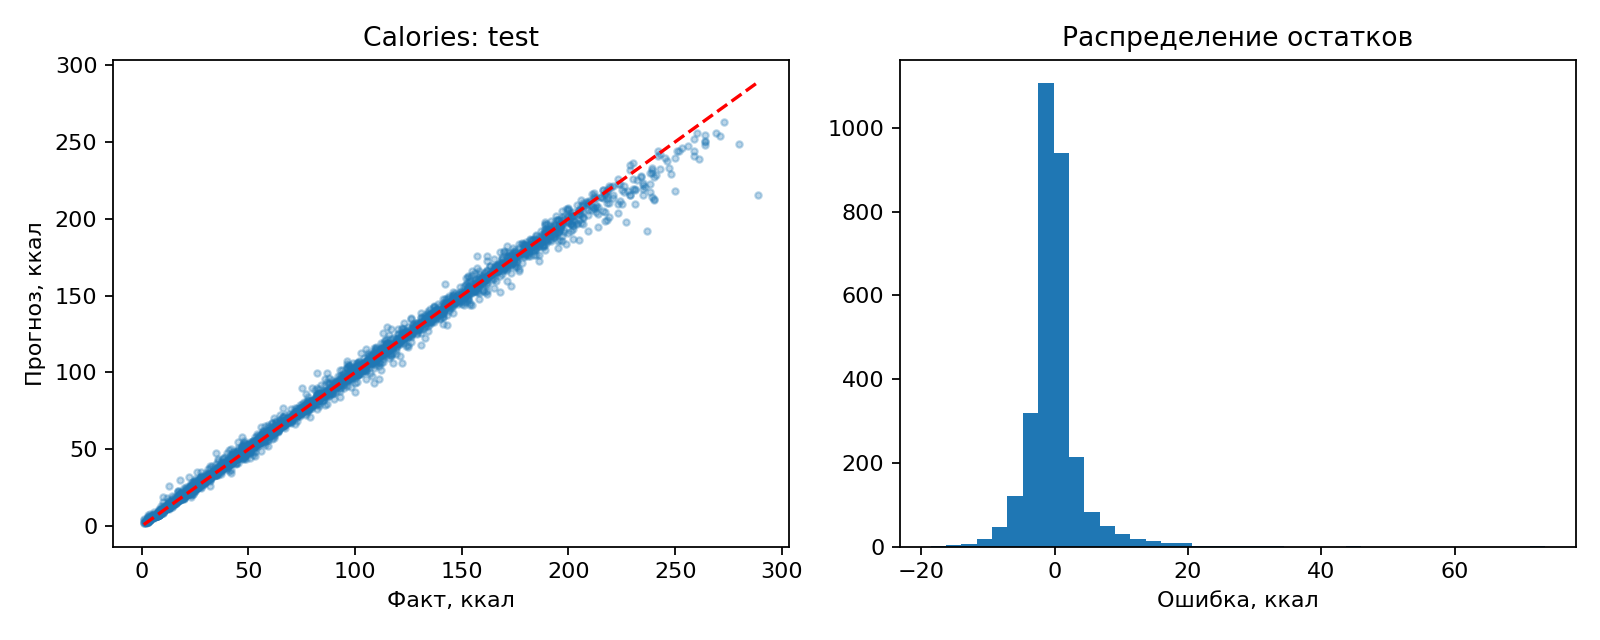

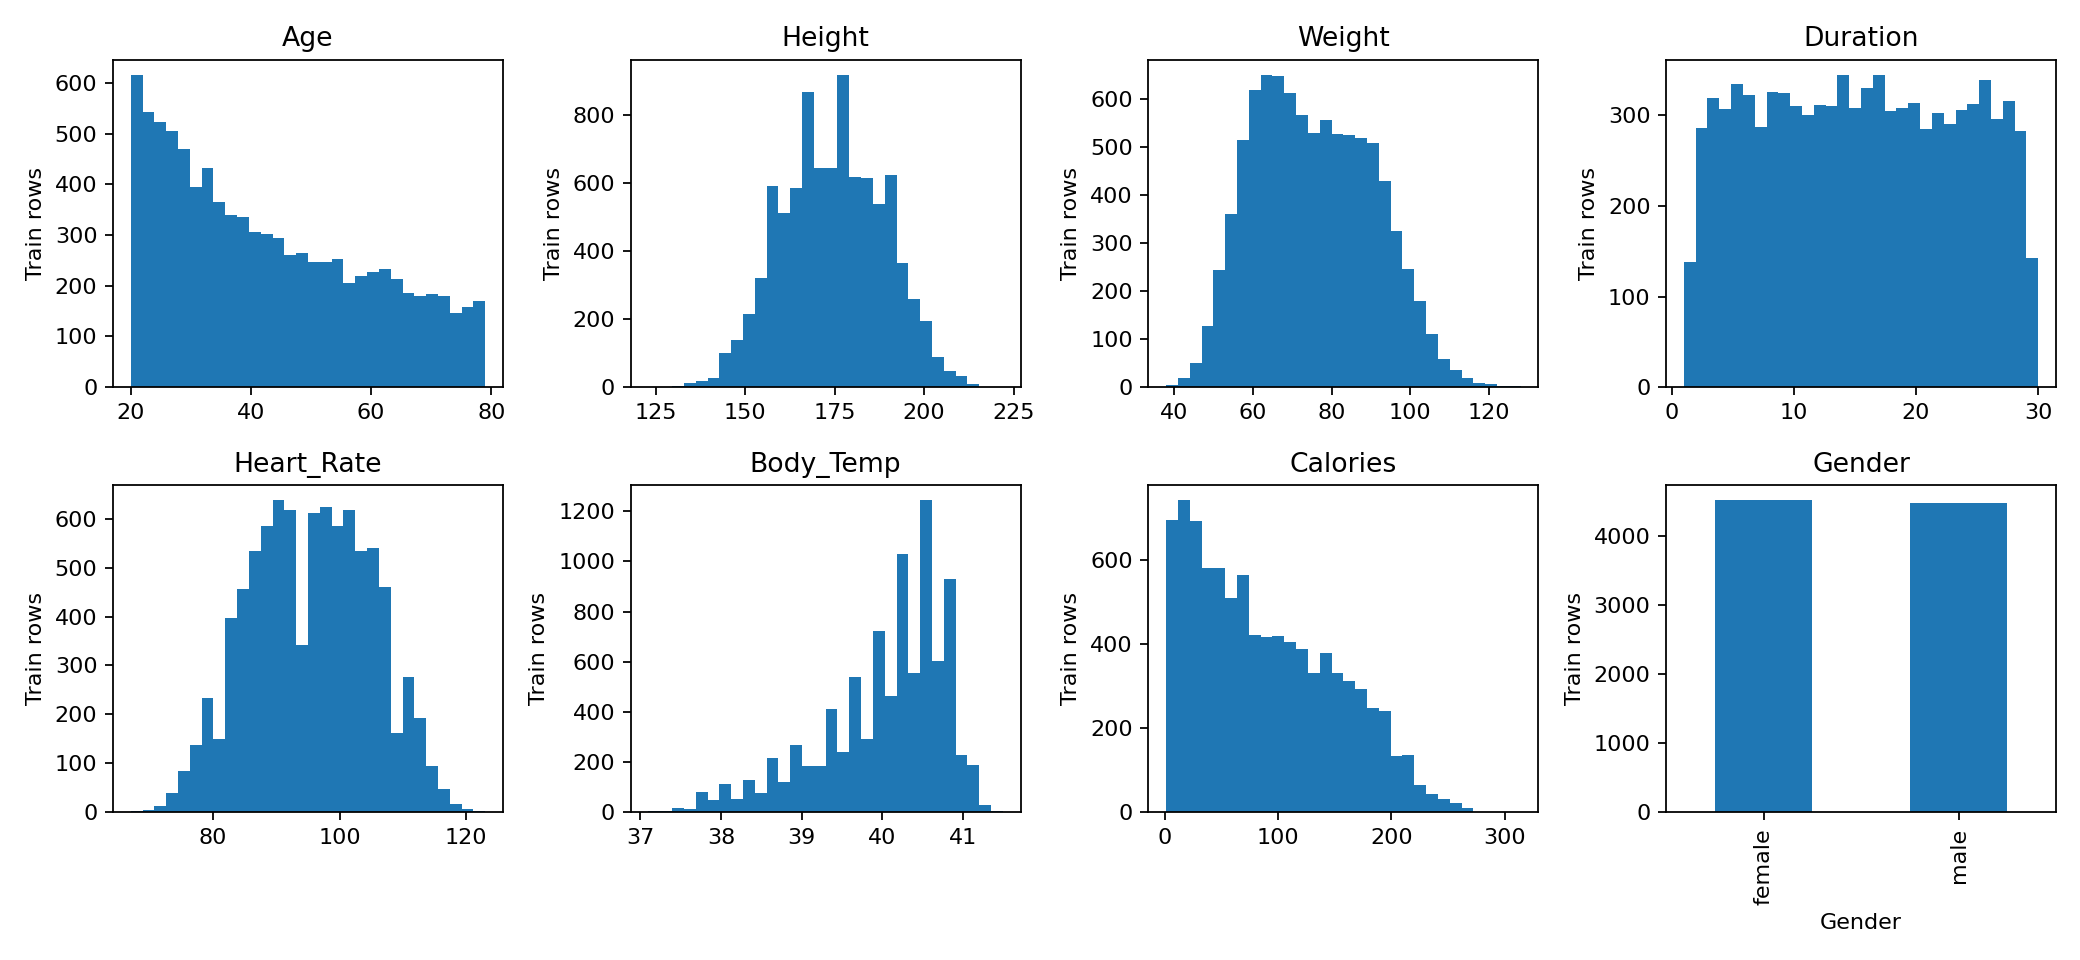

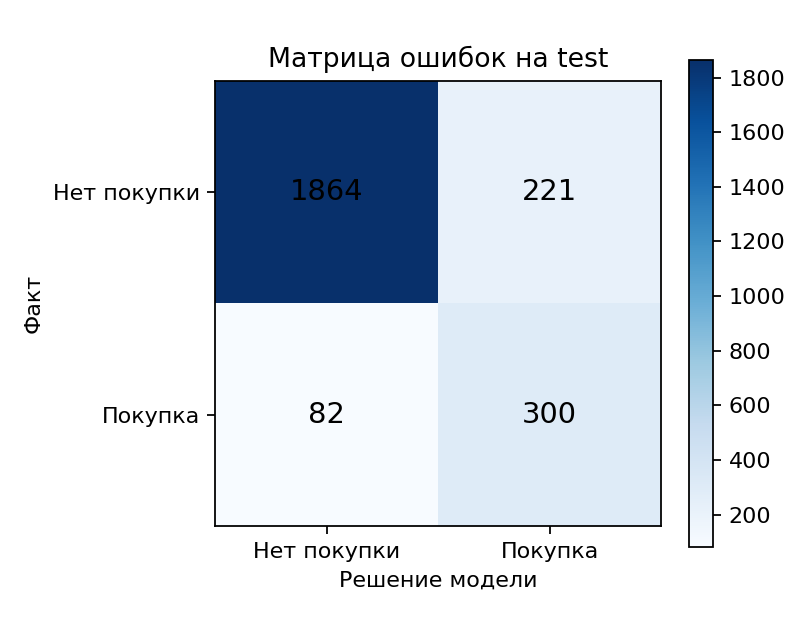

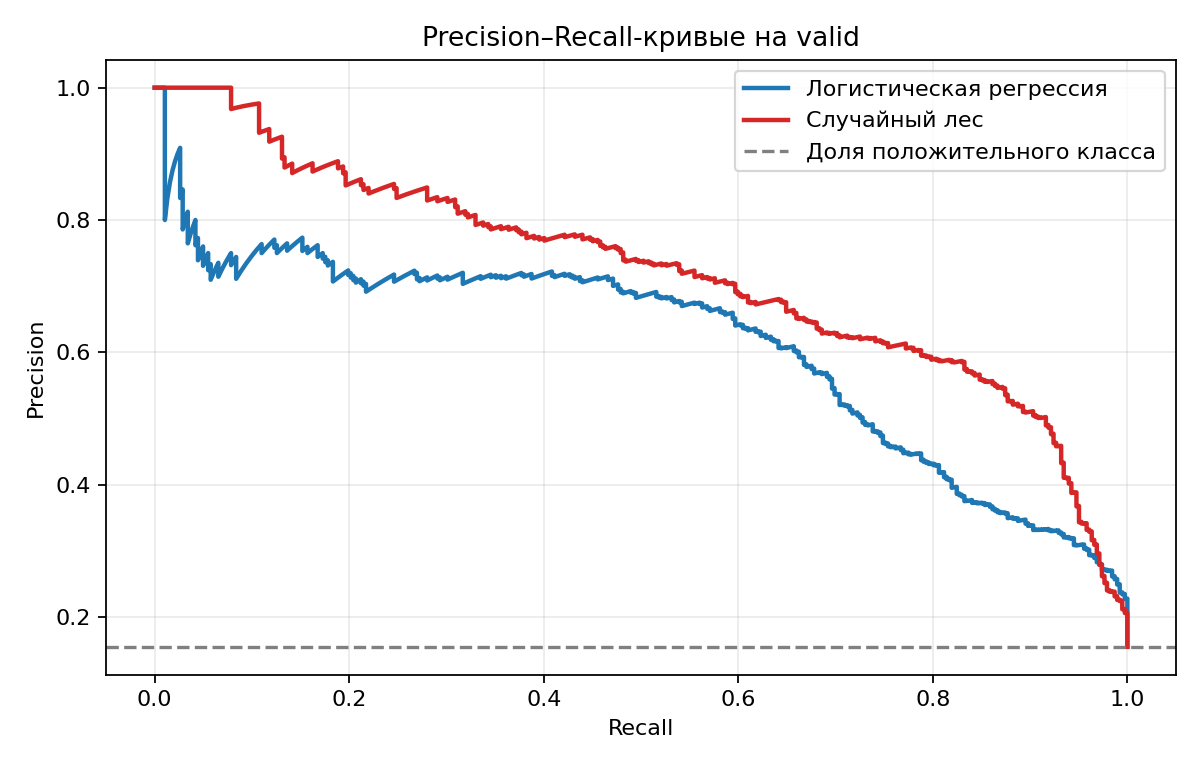

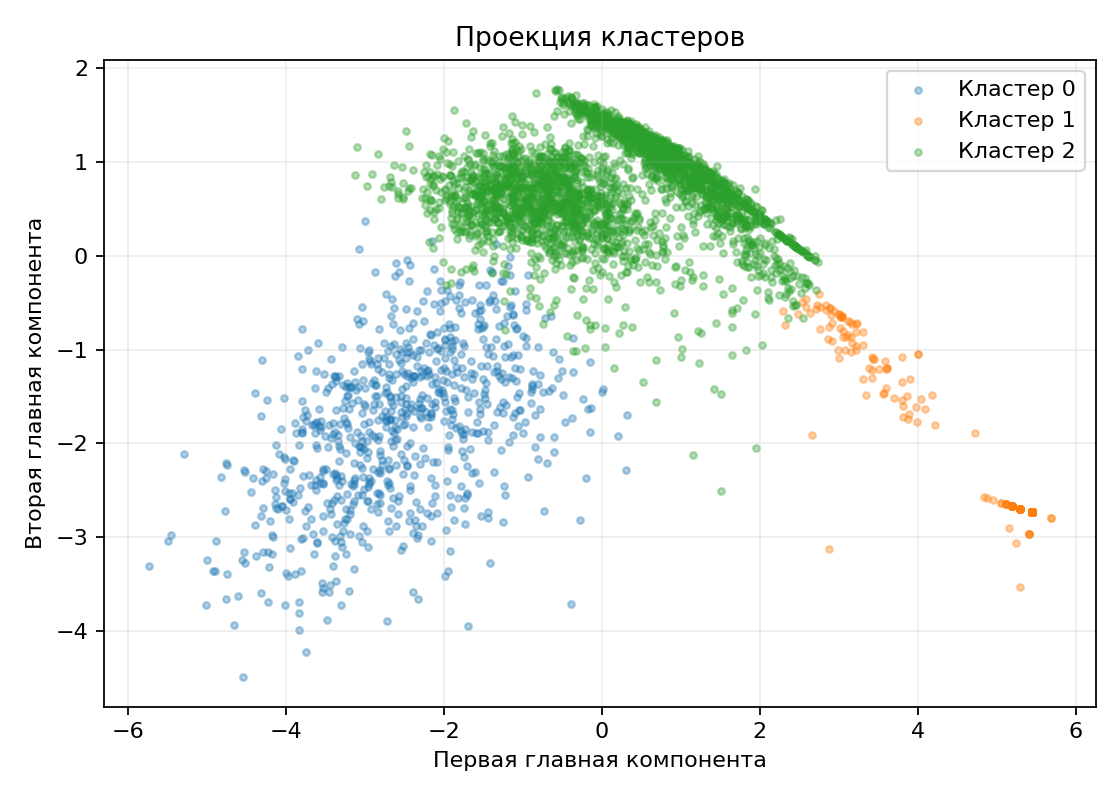

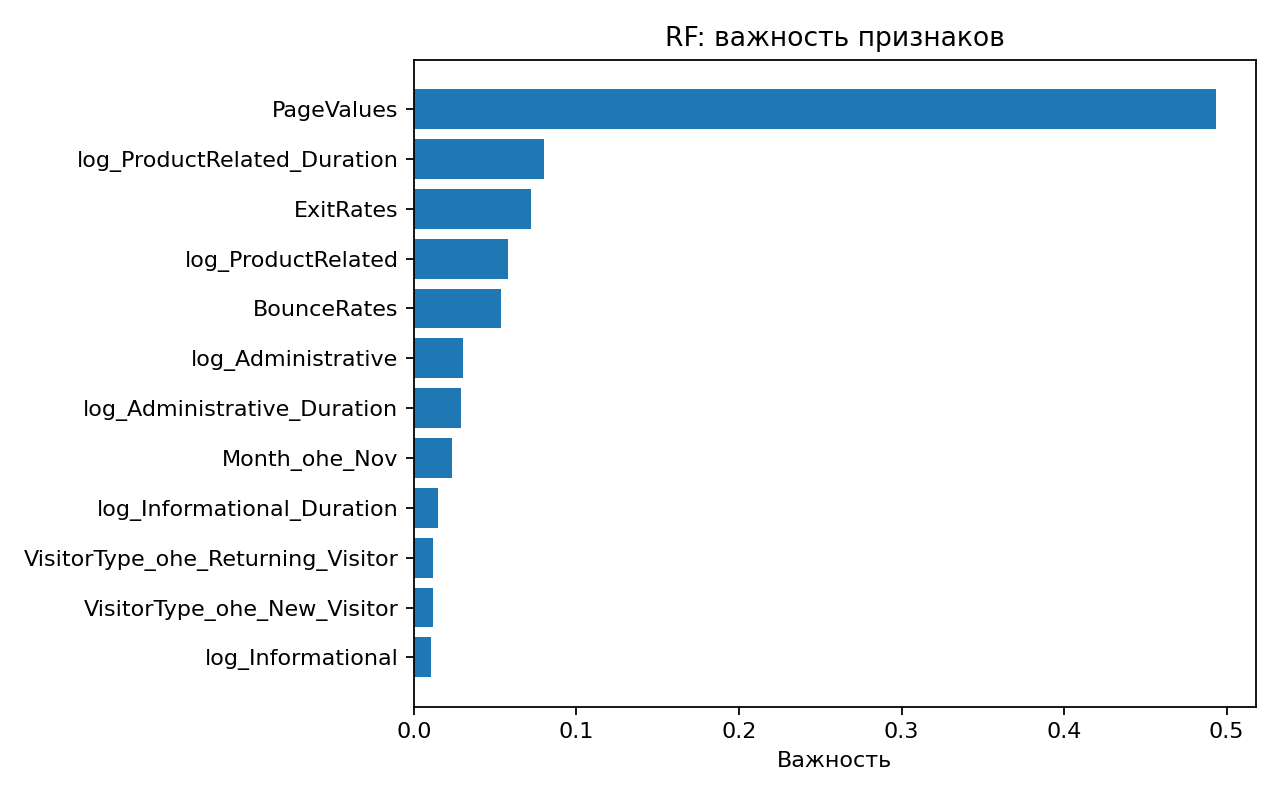

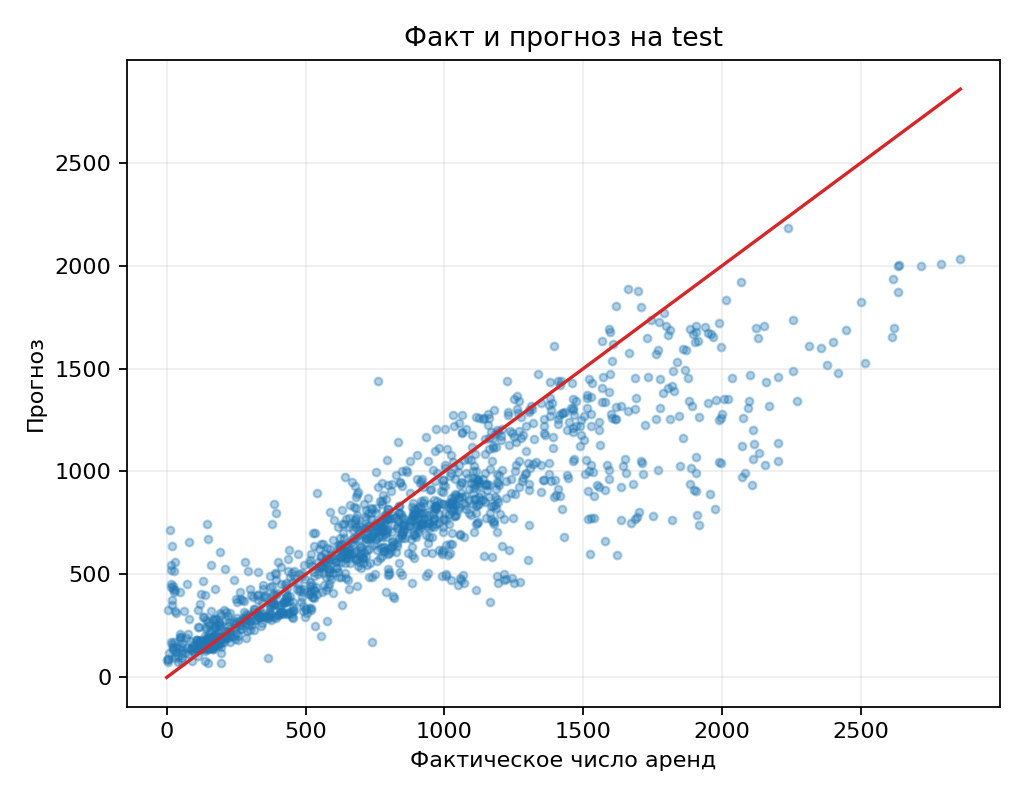

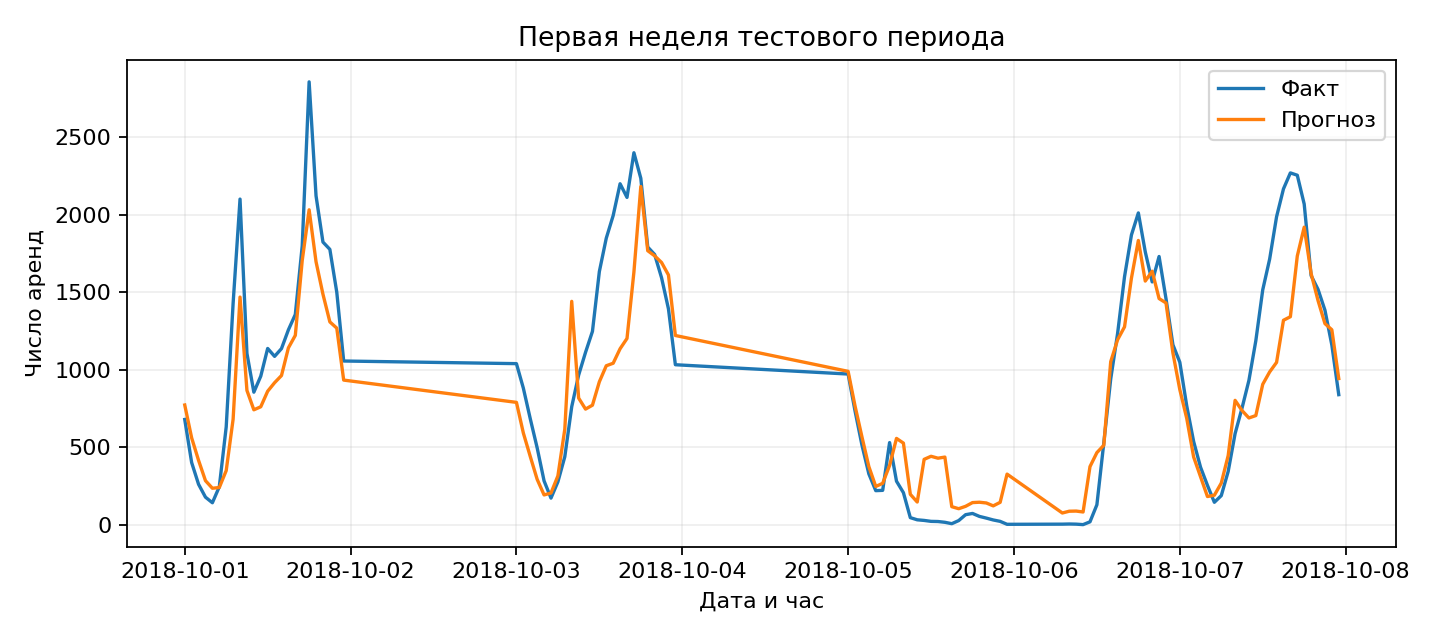

In [22]:

def rec(df):return [r.asDict(recursive=True) for r in df.collect()]
shop_validation.to_csv(OUT/'classification_validation.csv',index=False)
final_pd.sort_values('row_id').to_csv(OUT/'classification_test_predictions.csv',index=False)
reg_local[['timestamp','label','prediction','residual']].to_csv(OUT/'regression_test_predictions.csv',index=False)
bike_validation.to_csv(OUT/'regression_validation.csv',index=False)
k_table.to_csv(OUT/'kmeans_selection.csv',index=False)
cluster_profiles.toPandas().to_csv(OUT/'cluster_profiles.csv',index=False)
cluster_assignments.orderBy('row_id').toPandas().to_csv(OUT/'cluster_assignments.csv',index=False)
def feature_names(df,col='features'):
    attrs=df.schema[col].metadata.get('ml_attr',{}).get('attrs',{})
    return {a['idx']:a['name'] for group in attrs.values() for a in group}
rf=shop_models['Случайный лес'];fn=feature_names(rf.transform(shop_valid).select('features'))
importance=sorted([{'feature':fn.get(i,str(i)),'importance':float(v)} for i,v in enumerate(rf.stages[-1].featureImportances)],key=lambda x:-x['importance'])
lr=shop_models['Логистическая регрессия'];ln=feature_names(lr.transform(shop_valid),'features_raw')
coefficients=sorted([{'feature':ln.get(i,str(i)),'coefficient':float(v)} for i,v in enumerate(lr.stages[-1].coefficients)],key=lambda x:-abs(x['coefficient']))
fig,ax=plt.subplots(figsize=(8,5));top=importance[:12][::-1];ax.barh([x['feature'] for x in top],[x['importance'] for x in top]);ax.set(title='RF: важность признаков',xlabel='Важность');fig.tight_layout();fig.savefig(OUT/'feature_importance.png',dpi=160);plt.show();plt.close(fig)
loaded_shop=PipelineModel.load(str(MODELS/'shop_classifier'))
roundtrip_shop=binary_scores(loaded_shop,shop_test).exceptAll(shop_test_scores).count()
loaded_bike=PipelineModel.load(str(MODELS/'bike_regressor'))
roundtrip_bike=loaded_bike.transform(bike_test).select('date','hour','prediction').exceptAll(bike_test_prediction.select('date','hour','prediction')).count()
loaded_cluster=PipelineModel.load(str(MODELS/'shop_kmeans'))
roundtrip_cluster=loaded_cluster.transform(shop_raw).select('row_id',F.col('prediction').alias('cluster')).exceptAll(cluster_assignments).count()
assert roundtrip_shop==roundtrip_bike==roundtrip_cluster==0
baseline_valid=binary_metrics(shop_valid.withColumn('score',F.lit(0.0)),ranking=False)
summary={'environment':{'python':platform.python_version(),'spark':spark.version,'master':sc.master,'parallelism':sc.defaultParallelism,'java':subprocess.run(['java','-version'],capture_output=True,text=True).stderr.splitlines()[0]},
 'sources':json.loads((ROOT/'source_manifest.json').read_text()),
 'classification':{'raw_rows':shop_raw.count(),'class_counts':rec(shop_raw.groupBy('Revenue').count()),'split':rec(shop_split.groupBy('split','label').count()),'validation':shop_rows,'selected_model':BEST_SHOP_NAME,'threshold':SHOP_THRESHOLD,'test':binary_metrics(shop_test_scores,SHOP_THRESHOLD),'baseline_valid':baseline_valid,'ablation_with':binary_metrics(shop_valid_predictions['Случайный лес'])['areaUnderPR'],'ablation_without':binary_metrics(without_scores)['areaUnderPR'],'importance':importance,'coefficients':coefficients},
 'regression':{'raw_rows':8760,'working_rows':bike.count(),'split':{name:{'n':df.count(),'start':str(df.agg(F.min('date')).first()[0]),'end':str(df.agg(F.max('date')).first()[0])} for name,df in [('train',bike_train),('valid',bike_valid),('test',bike_test)]},'validation':json.loads(bike_validation.to_json(orient='records')),'selected_model':BEST_BIKE_NAME,'test':regression_metrics(bike_test_prediction),'baseline_test':[{'name':name,**regression_metrics(bike_baseline(bike_test,hour))} for name,hour in [('global',False),('hour',True)]]},
 'clustering':{'rows':shop_raw.count(),'features':CLUSTER_LOG_SOURCE+CLUSTER_RATE,'k_selection':k_rows,'selected_k':BEST_K,'profiles':rec(cluster_profiles),'pca_explained_variance':[float(v) for v in pca_model.explainedVariance]},
 'roundtrip_differences':{'classification':roundtrip_shop,'regression':roundtrip_bike,'kmeans':roundtrip_cluster},'independent':own_summary}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('SUMMARY SAVED',OUT/'summary.json')
from IPython.display import display, Image as DisplayImage
for saved_plot in sorted(OUT.glob('*.png')):
    display(DisplayImage(filename=str(saved_plot)))


## 10 Освобождение кэша и завершение

In [23]:
for pred in shop_valid_predictions.values():
    pred.unpersist()
for df in [shop_split, shop_test_scores, bike_train, bike_valid,
           bike_test, bike_test_prediction, shop_vectors, cluster_sample]:
    df.unpersist()

print("Готово. Результаты сохранены в", OUT)
spark.stop()
print("SparkSession stopped")


Готово. Результаты сохранены в /home/albakhtin/tiabd/АлбахтинИВ/ML/results/pr5


SparkSession stopped
